# Model performance

Evaluates the fine-tuned AP-10K pose model (`ap10k_ft/weights/best.pt`) directly against `data/ap10k` (val split 1):

1. Bounding-box detection accuracy
2. Keypoint accuracy
3. Per-keypoint accuracy
4. Animal detection + pose association
5. Inference latency
6. FPS

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

WEIGHTS = Path("../ap10k_ft/weights/best.pt")
ANN_FILE = Path("../data/ap10k/annotations/ap10k-val-split1.json")
IMG_DIR = Path("../data/ap10k/data")

KPT_NAMES = [
    "left_eye", "right_eye", "nose", "neck", "root_of_tail",
    "left_shoulder", "left_elbow", "left_front_paw",
    "right_shoulder", "right_elbow", "right_front_paw",
    "left_hip", "left_knee", "left_back_paw",
    "right_hip", "right_knee", "right_back_paw",
]
IOU_THRESH = 0.5      # box match threshold
PCK_THRESH = 0.1       # keypoint correct if dist < PCK_THRESH * sqrt(gt_box_area)

## Load model + ground truth

In [2]:
model = YOLO(str(WEIGHTS))

coco = json.loads(ANN_FILE.read_text())
images_by_id = {im["id"]: im for im in coco["images"]}
gt_by_image = {}
for ann in coco["annotations"]:
    if ann.get("num_keypoints", 0) == 0:
        continue
    gt_by_image.setdefault(ann["image_id"], []).append(ann)

image_ids = sorted(gt_by_image)
print(f"{len(image_ids)} val images, {sum(len(v) for v in gt_by_image.values())} GT instances")

995 val images, 1272 GT instances


## Run inference over the val split

In [3]:
def xywh_to_xyxy(box):
    x, y, w, h = box
    return np.array([x, y, x + w, y + h], dtype=np.float32)


img_paths = [IMG_DIR / images_by_id[i]["file_name"] for i in image_ids]
predictions = {}  # image_id -> dict(boxes[N,4], scores[N], kpts[N,17,2])

all_results = []
BATCH = 16
for start in range(0, len(img_paths), BATCH):
    chunk = img_paths[start:start + BATCH]
    all_results.extend(model.predict(chunk, conf=0.25, verbose=False, batch=BATCH))
    if (start // BATCH) % 10 == 0:
        print(f"  {start + len(chunk)}/{len(img_paths)}")

for image_id, r in zip(image_ids, all_results):
    boxes = r.boxes.xyxy.cpu().numpy() if len(r.boxes) else np.zeros((0, 4), dtype=np.float32)
    scores = r.boxes.conf.cpu().numpy() if len(r.boxes) else np.zeros((0,), dtype=np.float32)
    kpts = r.keypoints.xy.cpu().numpy() if r.keypoints is not None and len(r.boxes) else np.zeros((0, 17, 2), dtype=np.float32)
    predictions[image_id] = {"boxes": boxes, "scores": scores, "kpts": kpts}

print(f"inference done on {len(predictions)} images")

  16/995


  176/995


  336/995


  496/995


  656/995


  816/995


  976/995


inference done on 995 images


## Ground-truth <-> prediction matching

Each predicted box is greedily matched (highest confidence first) to the best unmatched ground-truth box with IoU >= 0.5, mirroring standard detection evaluation. Keypoint and association metrics below are computed only from this matching, so a wrong box match directly shows up as a wrong pose.

In [4]:
def box_iou(a, b):
    """a: [N,4], b: [M,4] xyxy -> [N,M] IoU."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    ax1, ay1, ax2, ay2 = a[:, 0:1], a[:, 1:2], a[:, 2:3], a[:, 3:4]
    bx1, by1, bx2, by2 = b[:, 0], b[:, 1], b[:, 2], b[:, 3]
    inter_x1 = np.maximum(ax1, bx1)
    inter_y1 = np.maximum(ay1, by1)
    inter_x2 = np.minimum(ax2, bx2)
    inter_y2 = np.minimum(ay2, by2)
    inter = np.clip(inter_x2 - inter_x1, 0, None) * np.clip(inter_y2 - inter_y1, 0, None)
    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - inter
    return inter / np.clip(union, 1e-9, None)


def match_greedy(gt_boxes, pred_boxes, pred_scores, iou_thresh=IOU_THRESH):
    """Returns list of (gt_idx, pred_idx, iou) matches, plus unmatched gt/pred index lists."""
    order = np.argsort(-pred_scores)
    ious = box_iou(pred_boxes, gt_boxes)  # [P, G]
    matched_gt, matched_pred = set(), set()
    matches = []
    for p in order:
        if len(gt_boxes) == 0:
            break
        g = int(np.argmax(ious[p])) if len(ious[p]) else -1
        if g == -1 or g in matched_gt:
            candidates = [gg for gg in range(len(gt_boxes)) if gg not in matched_gt]
            if not candidates:
                continue
            g = max(candidates, key=lambda gg: ious[p, gg])
        if ious[p, g] >= iou_thresh:
            matches.append((g, int(p), float(ious[p, g])))
            matched_gt.add(g)
            matched_pred.add(int(p))
    unmatched_gt = [g for g in range(len(gt_boxes)) if g not in matched_gt]
    unmatched_pred = [p for p in range(len(pred_boxes)) if p not in matched_pred]
    return matches, unmatched_gt, unmatched_pred


all_matches = []  # (image_id, gt_ann, pred_boxes_row, pred_kpts_row, iou)
n_gt = n_pred = n_tp = 0

for image_id in image_ids:
    anns = gt_by_image[image_id]
    gt_boxes = np.stack([xywh_to_xyxy(a["bbox"]) for a in anns])
    pred = predictions[image_id]

    matches, unmatched_gt, unmatched_pred = match_greedy(gt_boxes, pred["boxes"], pred["scores"])

    n_gt += len(anns)
    n_pred += len(pred["boxes"])
    n_tp += len(matches)

    for g, p, iou in matches:
        all_matches.append((image_id, anns[g], pred["boxes"][p], pred["kpts"][p], iou))

n_fp = n_pred - n_tp
n_fn = n_gt - n_tp
print(f"GT instances={n_gt}  predictions={n_pred}  matched(TP)={n_tp}  FP={n_fp}  FN={n_fn}")

GT instances=1272  predictions=1325  matched(TP)=1191  FP=134  FN=81


## 1. Bounding-box detection accuracy

In [5]:
box_precision = n_tp / n_pred if n_pred else 0.0
box_recall = n_tp / n_gt if n_gt else 0.0
box_f1 = 2 * box_precision * box_recall / (box_precision + box_recall) if (box_precision + box_recall) else 0.0
mean_iou = float(np.mean([m[4] for m in all_matches])) if all_matches else 0.0

print(f"Box detection @ IoU>={IOU_THRESH}")
print(f"  precision = {box_precision:.4f}")
print(f"  recall    = {box_recall:.4f}")
print(f"  F1        = {box_f1:.4f}")
print(f"  mean IoU of matched boxes = {mean_iou:.4f}")

Box detection @ IoU>=0.5
  precision = 0.8989
  recall    = 0.9363
  F1        = 0.9172
  mean IoU of matched boxes = 0.8630


## 2. Keypoint accuracy

In [6]:
def gt_box_scale(bbox):
    _, _, w, h = bbox
    return np.sqrt(max(w * h, 1e-6))


n_correct = 0
n_visible = 0
per_kpt_correct = np.zeros(17, dtype=np.int64)
per_kpt_total = np.zeros(17, dtype=np.int64)

for image_id, ann, pred_box, pred_kpts, iou in all_matches:
    kpts = np.array(ann["keypoints"], dtype=np.float32).reshape(17, 3)
    scale = gt_box_scale(ann["bbox"])
    thresh = PCK_THRESH * scale

    visible = kpts[:, 2] > 0
    dist = np.linalg.norm(kpts[:, :2] - pred_kpts, axis=1)
    correct = visible & (dist < thresh)

    n_visible += int(visible.sum())
    n_correct += int(correct.sum())
    per_kpt_total += visible.astype(np.int64)
    per_kpt_correct += correct.astype(np.int64)

keypoint_accuracy = n_correct / n_visible if n_visible else 0.0
print(f"PCK@{PCK_THRESH} (dist < {PCK_THRESH} * sqrt(gt box area)), matched instances only")
print(f"  visible GT keypoints = {n_visible}")
print(f"  correct              = {n_correct}")
print(f"  keypoint accuracy    = {keypoint_accuracy:.4f}")

PCK@0.1 (dist < 0.1 * sqrt(gt box area)), matched instances only
  visible GT keypoints = 11860
  correct              = 9564
  keypoint accuracy    = 0.8064


## 3. Per-keypoint accuracy

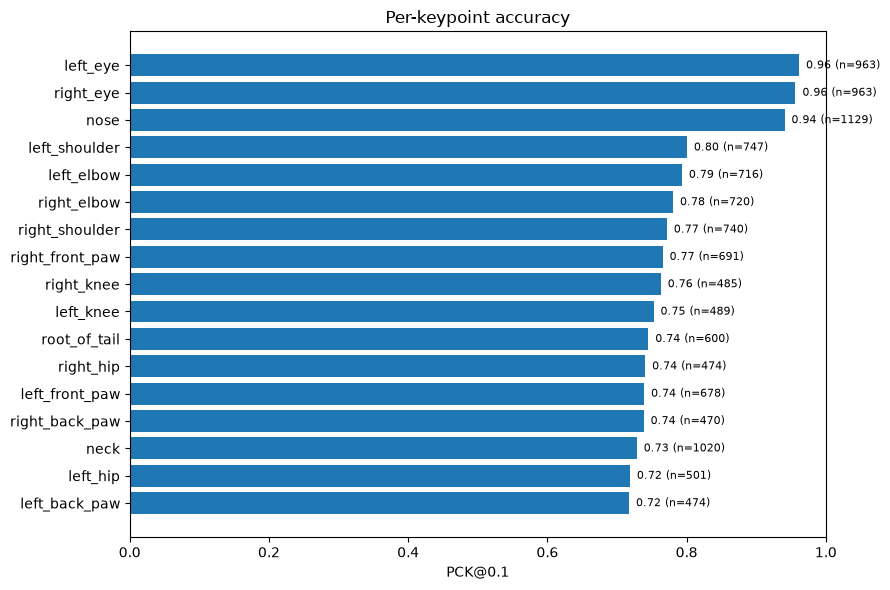

In [7]:
per_kpt_acc = np.divide(
    per_kpt_correct, per_kpt_total,
    out=np.zeros_like(per_kpt_correct, dtype=np.float64),
    where=per_kpt_total > 0,
)

order = np.argsort(per_kpt_acc)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([KPT_NAMES[i] for i in order], per_kpt_acc[order])
ax.set_xlabel(f"PCK@{PCK_THRESH}")
ax.set_xlim(0, 1)
ax.set_title("Per-keypoint accuracy")
for i, idx in enumerate(order):
    ax.text(per_kpt_acc[idx] + 0.01, i, f"{per_kpt_acc[idx]:.2f} (n={per_kpt_total[idx]})", va="center", fontsize=8)
fig.tight_layout()
plt.show()

## 4. Animal detection + pose association

Whether each detected animal's predicted keypoints stay attached to the *correct* animal, not a neighboring one. Reuses the IoU matching above: a wrong association would show up as a matched box with a good IoU but a poor keypoint score. Also checks multi-animal images specifically, where mismatched association is most likely.

In [8]:
multi_animal_images = [i for i in image_ids if len(gt_by_image[i]) > 1]

def image_pck(image_id):
    matches_here = [m for m in all_matches if m[0] == image_id]
    correct = total = 0
    for _, ann, _, pred_kpts, _ in matches_here:
        kpts = np.array(ann["keypoints"], dtype=np.float32).reshape(17, 3)
        scale = gt_box_scale(ann["bbox"])
        visible = kpts[:, 2] > 0
        dist = np.linalg.norm(kpts[:, :2] - pred_kpts, axis=1)
        correct += int((visible & (dist < PCK_THRESH * scale)).sum())
        total += int(visible.sum())
    return correct / total if total else None

single_pck = [image_pck(i) for i in image_ids if len(gt_by_image[i]) == 1]
multi_pck = [image_pck(i) for i in multi_animal_images]
single_pck = [v for v in single_pck if v is not None]
multi_pck = [v for v in multi_pck if v is not None]

fully_matched_multi = sum(
    1 for i in multi_animal_images
    if len([m for m in all_matches if m[0] == i]) == len(gt_by_image[i])
)

print(f"images with exactly 1 animal: {len(image_ids) - len(multi_animal_images)}")
print(f"images with >1 animal:        {len(multi_animal_images)}")
print(f"  of which all GT animals matched to a prediction: {fully_matched_multi} "
      f"({fully_matched_multi / len(multi_animal_images):.1%})" if multi_animal_images else "")
print(f"mean per-image PCK, single-animal images: {np.mean(single_pck):.4f}" if single_pck else "n/a")
print(f"mean per-image PCK, multi-animal images:  {np.mean(multi_pck):.4f}" if multi_pck else "n/a")

images with exactly 1 animal: 822
images with >1 animal:        173
  of which all GT animals matched to a prediction: 129 (74.6%)
mean per-image PCK, single-animal images: 0.8105
mean per-image PCK, multi-animal images:  0.7556


## 5. Inference latency

In [9]:
N_LATENCY = 100
latency_paths = img_paths[:N_LATENCY]

model.predict(latency_paths[0], verbose=False)  # warmup

times_ms = []
for p in latency_paths:
    t0 = time.perf_counter()
    model.predict(p, conf=0.25, verbose=False)
    times_ms.append((time.perf_counter() - t0) * 1000)

times_ms = np.array(times_ms)
print(f"single-image inference over {N_LATENCY} images (CPU, batch=1)")
print(f"  mean   = {times_ms.mean():.1f} ms")
print(f"  median = {np.median(times_ms):.1f} ms")
print(f"  p95    = {np.percentile(times_ms, 95):.1f} ms")
print(f"  min/max = {times_ms.min():.1f} / {times_ms.max():.1f} ms")

single-image inference over 100 images (CPU, batch=1)
  mean   = 116.1 ms
  median = 104.6 ms
  p95    = 180.3 ms
  min/max = 79.0 / 227.5 ms


## 6. FPS

In [10]:
fps_single = 1000.0 / times_ms.mean()

t0 = time.perf_counter()
model.predict(latency_paths, conf=0.25, verbose=False, batch=16)
batch_elapsed = time.perf_counter() - t0
fps_batch = len(latency_paths) / batch_elapsed

print(f"FPS (single-image, batch=1):  {fps_single:.2f}")
print(f"FPS (batched, batch=16):      {fps_batch:.2f}")

FPS (single-image, batch=1):  8.62
FPS (batched, batch=16):      6.23


## 7. Quantization comparison (FP32 vs FP16 vs INT8)

Exports the same finetuned checkpoint to ONNX at three precisions and reruns the six tests above (bounding-box accuracy, keypoint accuracy, per-keypoint accuracy, animal detection + pose association, latency, FPS) for each, on the identical val split. INT8 uses static calibration (ONNX Runtime) over a sample of the AP-10K train split.

In [11]:
import shutil

QUANT_DIR = Path("../ap10k_ft/weights_quant")
QUANT_DIR.mkdir(exist_ok=True)
CALIB_DIR = Path("../data/ap10k_calib")
N_CALIB = 300

### Build INT8 calibration set

ONNX Runtime static INT8 quantization needs a sample of real images (with YOLO-pose labels, purely for the dataloader) to estimate activation ranges. Built once from a random sample of the train split (not the val split used for evaluation, to avoid calibrating on test data); reused on rerun if it already exists.

In [12]:
def build_calibration_set(n=N_CALIB, seed=0):
    if (CALIB_DIR / "data.yaml").exists():
        print(f"calibration set already exists at {CALIB_DIR}")
        return CALIB_DIR / "data.yaml"

    import random

    train_ann = Path("../data/ap10k/annotations/ap10k-train-split1.json")
    coco_train = json.loads(train_ann.read_text())
    images_by_id_train = {im["id"]: im for im in coco_train["images"]}
    anns_by_image_train = {}
    for a in coco_train["annotations"]:
        if a.get("num_keypoints", 0) == 0:
            continue
        anns_by_image_train.setdefault(a["image_id"], []).append(a)

    ids = list(anns_by_image_train.keys())
    random.Random(seed).shuffle(ids)
    ids = ids[:n]

    (CALIB_DIR / "images").mkdir(parents=True, exist_ok=True)
    (CALIB_DIR / "labels").mkdir(parents=True, exist_ok=True)

    for iid in ids:
        im = images_by_id_train[iid]
        w, h = im["width"], im["height"]
        src = IMG_DIR / im["file_name"]
        dst_img = CALIB_DIR / "images" / im["file_name"]
        if not dst_img.exists():
            os.link(src, dst_img)

        lines = []
        for a in anns_by_image_train[iid]:
            x, y, bw, bh = a["bbox"]
            cx, cy, nw, nh = (x + bw / 2) / w, (y + bh / 2) / h, bw / w, bh / h
            row = [0, cx, cy, nw, nh]
            kpts = a["keypoints"]
            for i in range(17):
                kx, ky, kv = kpts[3 * i], kpts[3 * i + 1], kpts[3 * i + 2]
                row += [kx / w, ky / h, kv]
            lines.append(" ".join(f"{v:.6f}" if isinstance(v, float) else str(v) for v in row))
        (CALIB_DIR / "labels" / f"{Path(im['file_name']).stem}.txt").write_text("\n".join(lines))

    yaml_path = CALIB_DIR / "data.yaml"
    yaml_path.write_text(
        f"path: {CALIB_DIR.resolve()}\ntrain: images\nval: images\nkpt_shape: [17, 3]\nnames:\n  0: animal\n"
    )
    print(f"built calibration set: {len(ids)} images -> {CALIB_DIR}")
    return yaml_path


import os

calib_yaml = build_calibration_set()

built calibration set: 300 images -> ..\data\ap10k_calib


### Export FP32 / FP16 / INT8 ONNX models

In [13]:
def export_variant(quantize, suffix, data=None):
    dst = QUANT_DIR / f"best_{suffix}.onnx"
    if dst.exists():
        print(f"{suffix}: already exported -> {dst}")
        return dst
    kwargs = {"format": "onnx", "dynamic": True}
    if quantize is not None:
        kwargs["quantize"] = quantize
    if data is not None:
        kwargs["data"] = str(data)
    exported = Path(YOLO(str(WEIGHTS)).export(**kwargs))
    shutil.move(str(exported), dst)
    print(f"{suffix}: exported -> {dst}")
    return dst


fp32_path = export_variant(None, "fp32")
fp16_path = export_variant(16, "fp16")
int8_path = export_variant(8, "int8", data=calib_yaml)

Ultralytics 8.4.142  Python-3.14.6 torch-2.14.0+cpu CPU (Intel Core i5-8265U 1.60GHz)


YOLO26n-pose summary (fused): 129 layers, 2,926,494 parameters, 0 gradients, 7.6 GFLOPs



PyTorch: starting from '..\ap10k_ft\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 56, 8400) (7.4 MB)



ONNX: starting export with onnx 1.22.0 opset 18...


ONNX: slimming with onnxslim 0.1.96...


...

val: New cache created: C:\Users\anubh\Desktop\Projects\WildFrame\data\ap10k_calib\labels.cache


ONNX: quantizing INT8 with ONNX Runtime...


ONNX: export success  75.2s, saved as '..\ap10k_ft\weights\best_int8.onnx' (3.6 MB)



Export complete (76.1s)
Results saved to C:\Users\anubh\Desktop\Projects\WildFrame\ap10k_ft\weights\best_int8.onnx
Predict:         yolo predict task=pose model=..\ap10k_ft\weights\best_int8.onnx imgsz=640 
Validate:        yolo val task=pose model=..\ap10k_ft\weights\best_int8.onnx imgsz=640 data=/kaggle/working/ap10k-pose.yaml  
Visualize:       https://netron.app


int8: exported -> ..\ap10k_ft\weights_quant\best_int8.onnx


### Reusable evaluation routine (same 6 tests as above, parameterized by model)

In [14]:
def evaluate_model(weights_path, label, n_latency=N_LATENCY):
    model_q = YOLO(str(weights_path))

    # -- inference over the val split --
    preds_q = {}
    results_q = []
    for start in range(0, len(img_paths), BATCH):
        chunk = img_paths[start:start + BATCH]
        results_q.extend(model_q.predict(chunk, conf=0.25, verbose=False, batch=BATCH))
    for image_id, r in zip(image_ids, results_q):
        boxes = r.boxes.xyxy.cpu().numpy() if len(r.boxes) else np.zeros((0, 4), dtype=np.float32)
        scores = r.boxes.conf.cpu().numpy() if len(r.boxes) else np.zeros((0,), dtype=np.float32)
        kpts = (
            r.keypoints.xy.cpu().numpy()
            if r.keypoints is not None and len(r.boxes)
            else np.zeros((0, 17, 2), dtype=np.float32)
        )
        preds_q[image_id] = {"boxes": boxes, "scores": scores, "kpts": kpts}

    # -- GT <-> prediction matching --
    matches_q = []
    n_gt_q = n_pred_q = n_tp_q = 0
    for image_id in image_ids:
        anns = gt_by_image[image_id]
        gt_boxes = np.stack([xywh_to_xyxy(a["bbox"]) for a in anns])
        pred = preds_q[image_id]
        m, _, _ = match_greedy(gt_boxes, pred["boxes"], pred["scores"])
        n_gt_q += len(anns)
        n_pred_q += len(pred["boxes"])
        n_tp_q += len(m)
        for g, p, iou in m:
            matches_q.append((image_id, anns[g], pred["boxes"][p], pred["kpts"][p], iou))

    # -- 1. box detection accuracy --
    precision = n_tp_q / n_pred_q if n_pred_q else 0.0
    recall = n_tp_q / n_gt_q if n_gt_q else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    mean_iou = float(np.mean([m[4] for m in matches_q])) if matches_q else 0.0

    # -- 2 & 3. keypoint accuracy, per-keypoint accuracy --
    n_correct = n_visible = 0
    per_kpt_correct = np.zeros(17, dtype=np.int64)
    per_kpt_total = np.zeros(17, dtype=np.int64)
    for image_id, ann, pred_box, pred_kpts, iou in matches_q:
        kpts = np.array(ann["keypoints"], dtype=np.float32).reshape(17, 3)
        thresh = PCK_THRESH * gt_box_scale(ann["bbox"])
        visible = kpts[:, 2] > 0
        dist = np.linalg.norm(kpts[:, :2] - pred_kpts, axis=1)
        correct = visible & (dist < thresh)
        n_visible += int(visible.sum())
        n_correct += int(correct.sum())
        per_kpt_total += visible.astype(np.int64)
        per_kpt_correct += correct.astype(np.int64)
    keypoint_accuracy = n_correct / n_visible if n_visible else 0.0
    per_kpt_acc = np.divide(
        per_kpt_correct, per_kpt_total,
        out=np.zeros_like(per_kpt_correct, dtype=np.float64),
        where=per_kpt_total > 0,
    )

    # -- 4. animal detection + pose association --
    def image_pck_q(image_id):
        here = [m for m in matches_q if m[0] == image_id]
        correct = total = 0
        for _, ann, _, pred_kpts, _ in here:
            kpts = np.array(ann["keypoints"], dtype=np.float32).reshape(17, 3)
            visible = kpts[:, 2] > 0
            dist = np.linalg.norm(kpts[:, :2] - pred_kpts, axis=1)
            correct += int((visible & (dist < PCK_THRESH * gt_box_scale(ann["bbox"]))).sum())
            total += int(visible.sum())
        return correct / total if total else None

    fully_matched_multi = sum(
        1 for i in multi_animal_images
        if len([m for m in matches_q if m[0] == i]) == len(gt_by_image[i])
    )
    single_pck_q = [v for v in (image_pck_q(i) for i in image_ids if len(gt_by_image[i]) == 1) if v is not None]
    multi_pck_q = [v for v in (image_pck_q(i) for i in multi_animal_images) if v is not None]

    # -- 5. latency --
    latency_paths_q = img_paths[:n_latency]
    model_q.predict(latency_paths_q[0], verbose=False)  # warmup
    times_ms_q = []
    for p in latency_paths_q:
        t0 = time.perf_counter()
        model_q.predict(p, conf=0.25, verbose=False)
        times_ms_q.append((time.perf_counter() - t0) * 1000)
    times_ms_q = np.array(times_ms_q)

    # -- 6. FPS --
    fps_single_q = 1000.0 / times_ms_q.mean()
    t0 = time.perf_counter()
    model_q.predict(latency_paths_q, conf=0.25, verbose=False, batch=16)
    fps_batch_q = len(latency_paths_q) / (time.perf_counter() - t0)

    result = {
        "label": label,
        "box_precision": precision,
        "box_recall": recall,
        "box_f1": f1,
        "mean_iou": mean_iou,
        "keypoint_accuracy": keypoint_accuracy,
        "per_kpt_acc": per_kpt_acc,
        "fully_matched_multi_pct": fully_matched_multi / len(multi_animal_images) if multi_animal_images else 0.0,
        "single_pck": float(np.mean(single_pck_q)) if single_pck_q else 0.0,
        "multi_pck": float(np.mean(multi_pck_q)) if multi_pck_q else 0.0,
        "latency_mean_ms": float(times_ms_q.mean()),
        "latency_median_ms": float(np.median(times_ms_q)),
        "latency_p95_ms": float(np.percentile(times_ms_q, 95)),
        "fps_single": fps_single_q,
        "fps_batch": fps_batch_q,
        "onnx_size_mb": Path(weights_path).stat().st_size / 1e6,
    }
    print(
        f"[{label}] box P/R/F1={precision:.3f}/{recall:.3f}/{f1:.3f}  "
        f"IoU={mean_iou:.3f}  PCK@{PCK_THRESH}={keypoint_accuracy:.3f}  "
        f"latency={times_ms_q.mean():.1f}ms  fps={fps_single_q:.2f}  size={result['onnx_size_mb']:.1f}MB"
    )
    return result

### Run all three precisions

In [15]:
quant_results = [
    evaluate_model(fp32_path, "FP32"),
    evaluate_model(fp16_path, "FP16"),
    evaluate_model(int8_path, "INT8"),
]

Loading ..\ap10k_ft\weights_quant\best_fp32.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.30.0 with CPUExecutionProvider


[FP32] box P/R/F1=0.899/0.936/0.917  IoU=0.863  PCK@0.1=0.806  latency=90.4ms  fps=11.06  size=12.3MB


Loading ..\ap10k_ft\weights_quant\best_fp16.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.30.0 with CPUExecutionProvider


[FP16] box P/R/F1=0.899/0.936/0.917  IoU=0.863  PCK@0.1=0.806  latency=90.7ms  fps=11.03  size=6.4MB


Loading ..\ap10k_ft\weights_quant\best_int8.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.30.0 with CPUExecutionProvider


[INT8] box P/R/F1=0.876/0.932/0.903  IoU=0.850  PCK@0.1=0.775  latency=148.6ms  fps=6.73  size=3.8MB


### Comparison table

In [16]:
header = f"{'precision':<8}{'boxF1':>8}{'meanIoU':>9}{'PCK':>8}{'latency(ms)':>13}{'FPS':>8}{'size(MB)':>10}"
print(header)
print("-" * len(header))
for r in quant_results:
    print(
        f"{r['label']:<8}{r['box_f1']:>8.3f}{r['mean_iou']:>9.3f}{r['keypoint_accuracy']:>8.3f}"
        f"{r['latency_mean_ms']:>13.1f}{r['fps_single']:>8.2f}{r['onnx_size_mb']:>10.1f}"
    )

precision   boxF1  meanIoU     PCK  latency(ms)     FPS  size(MB)
-----------------------------------------------------------------
FP32       0.917    0.863   0.806         90.4   11.06      12.3
FP16       0.917    0.863   0.806         90.7   11.03       6.4
INT8       0.903    0.850   0.775        148.6    6.73       3.8


### Comparison plots

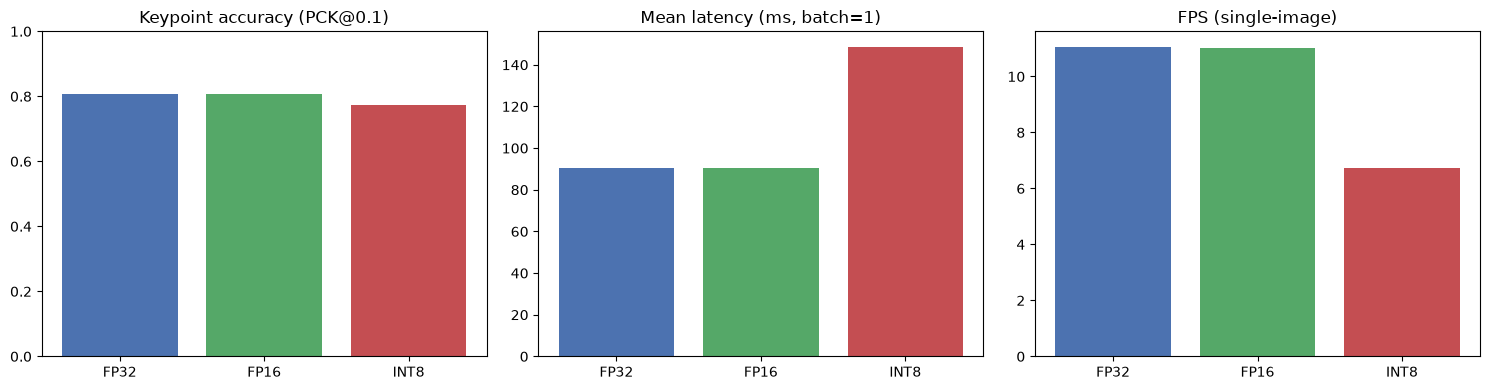

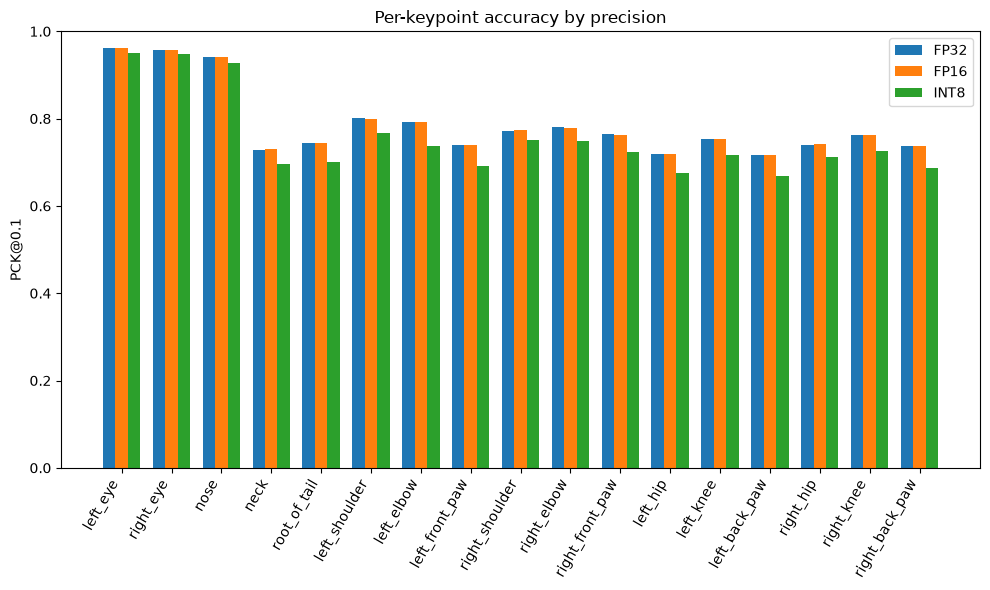

In [17]:
labels_q = [r["label"] for r in quant_results]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(labels_q, [r["keypoint_accuracy"] for r in quant_results], color=["#4c72b0", "#55a868", "#c44e52"])
axes[0].set_title(f"Keypoint accuracy (PCK@{PCK_THRESH})")
axes[0].set_ylim(0, 1)

axes[1].bar(labels_q, [r["latency_mean_ms"] for r in quant_results], color=["#4c72b0", "#55a868", "#c44e52"])
axes[1].set_title("Mean latency (ms, batch=1)")

axes[2].bar(labels_q, [r["fps_single"] for r in quant_results], color=["#4c72b0", "#55a868", "#c44e52"])
axes[2].set_title("FPS (single-image)")

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(17)
width = 0.25
for i, r in enumerate(quant_results):
    ax.bar(x + (i - 1) * width, r["per_kpt_acc"], width, label=r["label"])
ax.set_xticks(x)
ax.set_xticklabels(KPT_NAMES, rotation=60, ha="right")
ax.set_ylabel(f"PCK@{PCK_THRESH}")
ax.set_ylim(0, 1)
ax.set_title("Per-keypoint accuracy by precision")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Base model (pre-finetuning) comparison

How much did finetuning on AP-10K actually help? Evaluates the untouched pretrained checkpoint (`yolo26n-pose.pt`, COCO person-pose weights — same architecture, same `kpt_shape=[17,3]`, but never trained on animals) with the identical six tests, alongside the finetuned PyTorch model and the three quantized ONNX variants above.

In [18]:
BASE_WEIGHTS = Path("../pretrained/yolo26n-pose.pt")

base_result = evaluate_model(BASE_WEIGHTS, "Base (pretrained)")
finetuned_result = evaluate_model(WEIGHTS, "Finetuned (PT fp32)")

all_results = [base_result, finetuned_result] + quant_results

[Base (pretrained)] box P/R/F1=0.502/0.094/0.159  IoU=0.798  PCK@0.1=0.156  latency=134.3ms  fps=7.45  size=7.9MB


[Finetuned (PT fp32)] box P/R/F1=0.899/0.936/0.917  IoU=0.863  PCK@0.1=0.806  latency=117.0ms  fps=8.55  size=7.8MB


### Full comparison table

In [19]:
header = f"{'model':<20}{'boxF1':>8}{'meanIoU':>9}{'PCK':>8}{'latency(ms)':>13}{'FPS':>8}{'size(MB)':>10}"
print(header)
print("-" * len(header))
for r in all_results:
    print(
        f"{r['label']:<20}{r['box_f1']:>8.3f}{r['mean_iou']:>9.3f}{r['keypoint_accuracy']:>8.3f}"
        f"{r['latency_mean_ms']:>13.1f}{r['fps_single']:>8.2f}{r['onnx_size_mb']:>10.1f}"
    )

model                  boxF1  meanIoU     PCK  latency(ms)     FPS  size(MB)
----------------------------------------------------------------------------
Base (pretrained)      0.159    0.798   0.156        134.3    7.45       7.9
Finetuned (PT fp32)    0.917    0.863   0.806        117.0    8.55       7.8
FP32                   0.917    0.863   0.806         90.4   11.06      12.3
FP16                   0.917    0.863   0.806         90.7   11.03       6.4
INT8                   0.903    0.850   0.775        148.6    6.73       3.8


### Full comparison plots

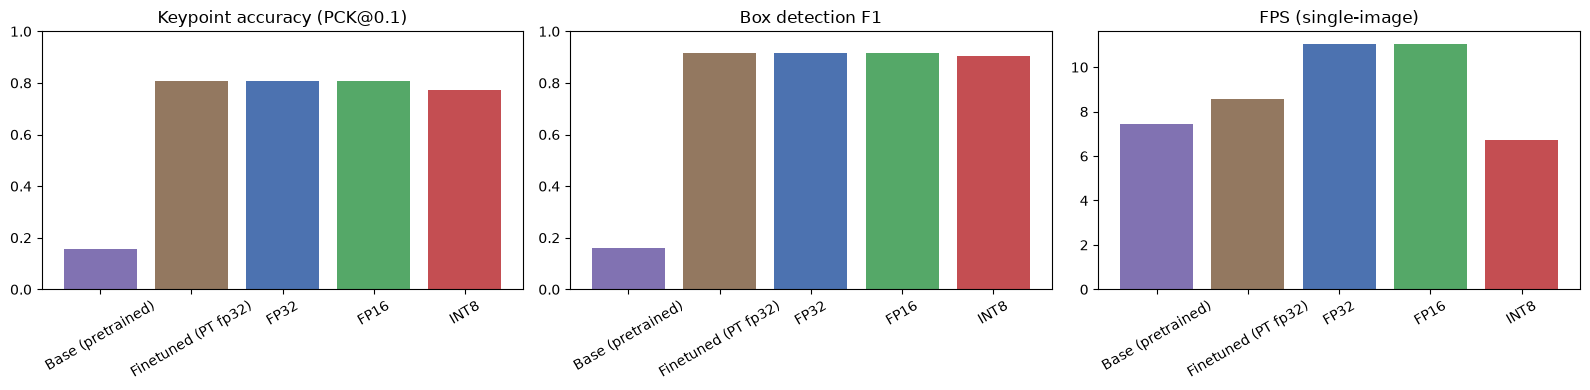

In [20]:
labels_all = [r["label"] for r in all_results]
colors_all = ["#8172b2", "#937860", "#4c72b0", "#55a868", "#c44e52"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(labels_all, [r["keypoint_accuracy"] for r in all_results], color=colors_all)
axes[0].set_title(f"Keypoint accuracy (PCK@{PCK_THRESH})")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(labels_all, [r["box_f1"] for r in all_results], color=colors_all)
axes[1].set_title("Box detection F1")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=30)

axes[2].bar(labels_all, [r["fps_single"] for r in all_results], color=colors_all)
axes[2].set_title("FPS (single-image)")
axes[2].tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()